<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/solitons/soliton_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*TASI Lectures on Solitons* — `soliton_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Solitons — Comprehensive Visualization Notebook
**Based on D. Tong, TASI Lectures on Solitons (davidtong.org/teaching/solitons/)**

8 key visualizations, two per chapter (Ch 1–4).

| Plot | Ch | Figure | Topic |
|-----|----|--------|-------|
| 1 | 1 | fig01 | Soliton hierarchy web: embeddings and constructions |
| 2 | 1 | fig02 | BPST instanton: action density profile |
| 3 | 2 | fig01 | 't Hooft–Polyakov monopole: field profiles |
| 4 | 2 | fig03 | Nahm construction: interval data → monopole fields |
| 5 | 3 | fig01 | Abrikosov vortex: field profiles |
| 6 | 3 | fig02 | Vortex 90° scattering via geodesic approximation |
| 7 | 4 | fig01 | BPS domain wall: kink profile and multi-wall ordering |
| 8 | 4 | fig03 | Complete soliton web and worldvolume theories |

Run **Setup** first, then any plot cell independently.


In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
AMB  = '#e8a838'; YELL = '#f9c74f'; GREEN = '#90ee90'
RED  = '#e07070'; PURP = '#c792ea'; BLUE = '#89c4f4'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.25,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMB, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

os.makedirs('soliton_visualizations', exist_ok=True)

def save(name, fig):
    fig.savefig(f'soliton_visualizations/{name}', dpi=150,
                bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: soliton_visualizations/{name}')

print('Setup complete.')


Setup complete.


## Plot 1: Ch 1 · Classical Solitons — Soliton Hierarchy Web

The four solitons (instanton, monopole, vortex, domain wall) and their embedding chain.
Each soliton lives inside the worldvolume theory of the next; constructions shown below each node.


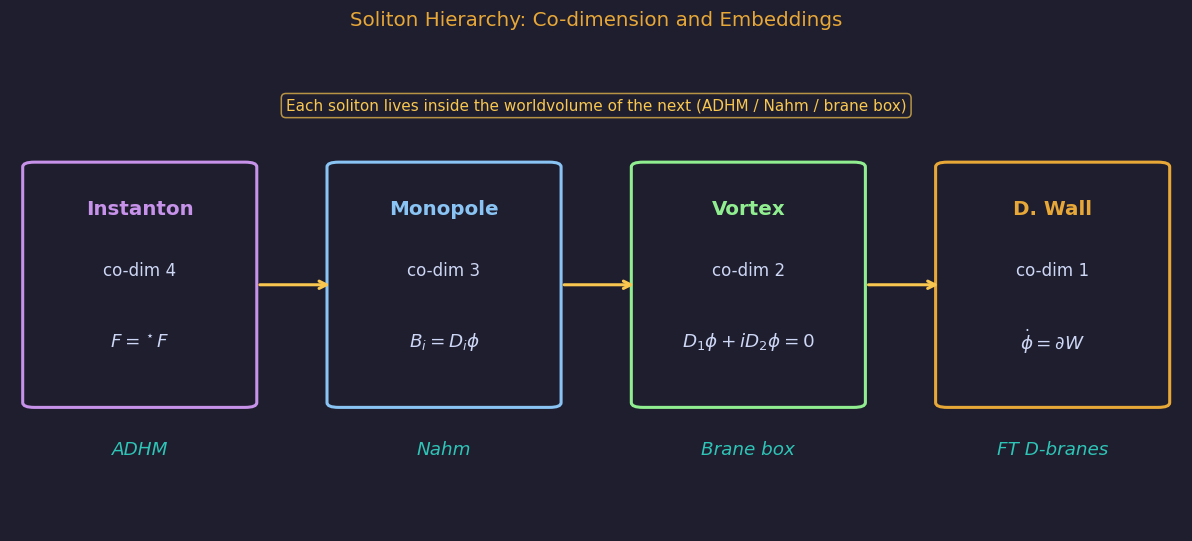

Saved: soliton_visualizations/ch01_fig01_soliton_web.png


In [2]:
# ── fig01: soliton hierarchy web ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
fig.suptitle("Soliton Hierarchy: Co-dimension and Embeddings", color=AMB, fontsize=13)
ax.set_facecolor(BG); ax.axis('off')

solitons = [
    (0.12, 0.52, "Instanton", "co-dim 4", r"$F={}^\star F$",       PURP),
    (0.38, 0.52, "Monopole",  "co-dim 3", r"$B_i=D_i\phi$",        BLUE),
    (0.64, 0.52, "Vortex",    "co-dim 2", r"$D_1\phi+iD_2\phi=0$", GREEN),
    (0.90, 0.52, "D. Wall",   "co-dim 1", r"$\dot\phi=\partial W$", AMB),
]
for (x, y, name, codim, eqn, col) in solitons:
    rect = FancyBboxPatch((x-0.10, y-0.25), 0.18, 0.50,
                          boxstyle="round,pad=0.01", lw=2,
                          edgecolor=col, facecolor=BG, transform=ax.transAxes, zorder=3)
    ax.add_patch(rect)
    ax.text(x-0.01, y+0.16, name,  ha='center', va='center', fontsize=13,
            fontweight='bold', color=col, transform=ax.transAxes)
    ax.text(x-0.01, y+0.03, codim, ha='center', va='center', fontsize=11,
            color=FG, transform=ax.transAxes)
    ax.text(x-0.01, y-0.12, eqn,  ha='center', va='center', fontsize=12,
            color=FG, transform=ax.transAxes)

for x0, x1 in [(0.22, 0.28), (0.48, 0.54), (0.74, 0.80)]:
    ax.annotate('', xy=(x1-0.005, 0.52), xytext=(x0-0.01, 0.52),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color=YELL, lw=2.0))

ax.text(0.50, 0.90, "Each soliton lives inside the worldvolume of the next (ADHM / Nahm / brane box)",
        ha='center', va='center', fontsize=10, color=YELL, transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELL, alpha=0.7))

labels = ["ADHM", "Nahm", "Brane box", "FT D-branes"]
for x, lbl in zip([0.12, 0.38, 0.64, 0.90], labels):
    ax.text(x-0.01, 0.17, lbl, ha='center', va='center', fontsize=12,
            color=TEAL, transform=ax.transAxes, style='italic')

plt.tight_layout()
save('ch01_fig01_soliton_web.png', fig)


## Plot 2: Ch 1 · Instantons — BPST Action Density Profile

Left: contour plot of $\mathrm{Tr}\,F^2$ in the $x^1$-$x^2$ plane for the $k=1$ BPST instanton.
Right: radial profiles for different instanton sizes $\rho$; small $\rho$ gives a spiky UV-divergent lump.


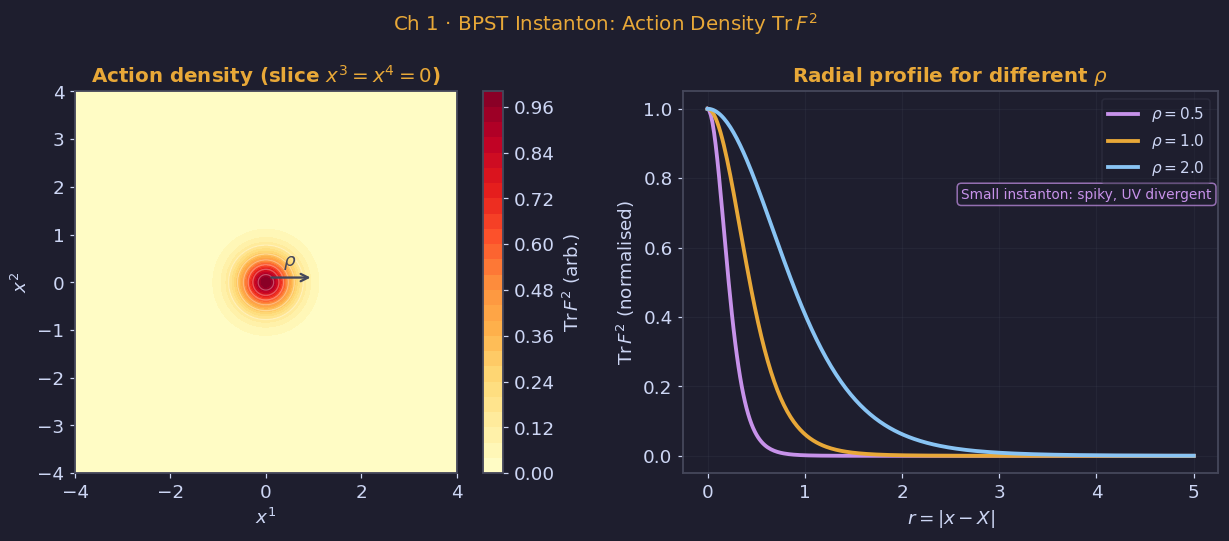

Saved: soliton_visualizations/ch01_fig02_instanton_profile.png


In [3]:
# ── fig02: BPST instanton action density ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 1 · BPST Instanton: Action Density $\mathrm{Tr}\,F^2$", color=AMB, fontsize=13)

x = np.linspace(-4, 4, 200); y = np.linspace(-4, 4, 200)
X, Y = np.meshgrid(x, y)
rho = 1.0; r2 = X**2 + Y**2
action = rho**4 / (r2 + rho**2)**4

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"Action density (slice $x^3=x^4=0$)", color=AMB)
cf = ax.contourf(X, Y, action, levels=30, cmap='YlOrRd')
plt.colorbar(cf, ax=ax, label=r'$\mathrm{Tr}\,F^2$ (arb.)')
ax.contour(X, Y, action, levels=8, colors='white', alpha=0.3, linewidths=0.8)
ax.set_xlabel(r'$x^1$'); ax.set_ylabel(r'$x^2$'); ax.set_aspect('equal')
ax.annotate('', xy=(rho, 0.1), xytext=(0.05, 0.1),
            arrowprops=dict(arrowstyle='->', color=EDGE, lw=1.5))
ax.text(rho/2, 0.35, r'$\rho$', ha='center', color=EDGE, fontsize=12)

ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"Radial profile for different $\rho$", color=AMB)
r = np.linspace(0, 5, 300)
for rho_val, col, lbl in [(0.5, PURP, r'$\rho=0.5$'), (1.0, AMB, r'$\rho=1.0$'),
                           (2.0, BLUE, r'$\rho=2.0$')]:
    prof = rho_val**4 / (r**2 + rho_val**2)**4
    ax2.plot(r, prof/prof.max(), color=col, lw=2.5, label=lbl)
ax2.set_xlabel(r'$r = |x - X|$'); ax2.set_ylabel(r'$\mathrm{Tr}\,F^2$ (normalised)')
ax2.legend(fontsize=10); ax2.grid(True, alpha=0.2)
ax2.text(0.52, 0.72, "Small instanton: spiky, UV divergent",
         transform=ax2.transAxes, fontsize=9, color=PURP,
         bbox=dict(boxstyle='round', fc=BG, ec=PURP, alpha=0.7))

plt.tight_layout()
save('ch01_fig02_instanton_profile.png', fig)


## Plot 3: Ch 2 · Monopoles — 't Hooft–Polyakov Field Profiles

Left: BPS Higgs field $|\phi|/v$ and magnetic field $B_r$; core is non-Abelian, tail falls as $1/r^2$.
Right: radial magnetic field lines showing the Coulomb-like magnetic charge at large $r$.


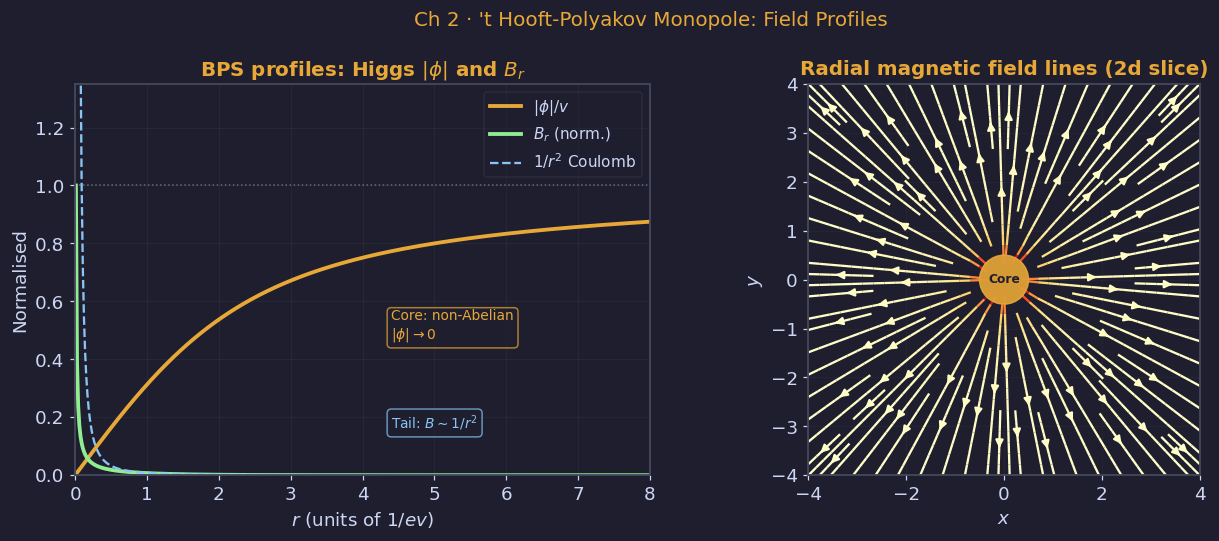

Saved: soliton_visualizations/ch02_fig01_monopole_profile.png


In [4]:
# ── fig01: 't Hooft-Polyakov monopole profiles ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 2 · 't Hooft-Polyakov Monopole: Field Profiles", color=AMB, fontsize=13)

r = np.linspace(0.01, 8.0, 500); v = 1.0
phi = v*(1.0/np.tanh(v*r) - 1.0/(v*r))
B_r = v**2*r/np.sinh(v*r)**2
B_asym = 1.0/r**2

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"BPS profiles: Higgs $|\phi|$ and $B_r$", color=AMB)
ax.plot(r, phi/v,           color=AMB,   lw=2.5, label=r'$|\phi|/v$')
ax.plot(r, B_r/B_r.max(),   color=GREEN, lw=2.5, label=r'$B_r$ (norm.)')
ax.plot(r, np.minimum(B_asym/B_asym[5], 1.5), color=BLUE, lw=1.5,
        ls='--', label=r'$1/r^2$ Coulomb')
ax.axhline(1.0, color=FG, ls=':', lw=1, alpha=0.4)
ax.set_xlabel(r'$r$ (units of $1/ev$)'); ax.set_ylabel('Normalised')
ax.set_ylim(0, 1.35); ax.set_xlim(0, 8)
ax.legend(fontsize=10); ax.grid(True, alpha=0.2)
ax.text(0.55, 0.35, "Core: non-Abelian\n" + r"$|\phi|\to 0$", transform=ax.transAxes,
        fontsize=9, color=AMB, bbox=dict(boxstyle='round', fc=BG, ec=AMB, alpha=0.7))
ax.text(0.55, 0.12, r"Tail: $B\sim 1/r^2$", transform=ax.transAxes,
        fontsize=9, color=BLUE, bbox=dict(boxstyle='round', fc=BG, ec=BLUE, alpha=0.7))

ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"Radial magnetic field lines (2d slice)", color=AMB)
x2 = np.linspace(-4, 4, 20); y2 = np.linspace(-4, 4, 20)
Xg, Yg = np.meshgrid(x2, y2)
R2 = np.sqrt(Xg**2 + Yg**2) + 0.1
Bx = Xg/R2**3; By = Yg/R2**3
ax2.streamplot(x2, y2, Bx, By, color=np.sqrt(Bx**2+By**2),
               cmap='YlOrRd', linewidth=1.5, density=1.2)
ax2.add_patch(plt.Circle((0,0), 0.5, color=AMB, zorder=5, alpha=0.9))
ax2.text(0, 0, 'Core', ha='center', va='center', fontsize=8,
         color=BG, fontweight='bold', zorder=6)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$')
ax2.set_xlim(-4,4); ax2.set_ylim(-4,4); ax2.set_aspect('equal')
ax2.grid(True, alpha=0.15)
plt.tight_layout()
save('ch02_fig01_monopole_profile.png', fig)


## Plot 4: Ch 2 · Monopoles — Nahm Construction (Revised)

Nahm data $T_i(\zeta)$ on the interval $[0,1]$ satisfying Nahm's equations; solved via a Weyl equation
to yield monopole fields $(A_i,\phi)$ in $\mathbf{R}^3$ satisfying the Bogomolny equations $B_i=D_i\phi$.


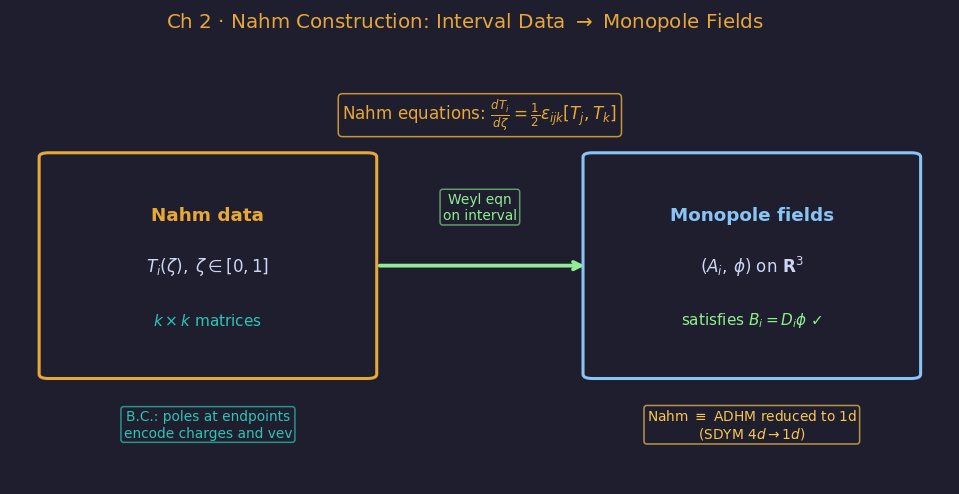

Saved: soliton_visualizations/ch02_fig03_nahm_construction.png


In [5]:
# ── fig03: Nahm construction schematic (revised) ─────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
fig.suptitle(r"Ch 2 · Nahm Construction: Interval Data $\to$ Monopole Fields",
             color=AMB, fontsize=13)
ax.set_facecolor(BG); ax.axis('off')

# ── 박스 경계 좌표 (axes fraction) ──────────────────────────────────────
# 왼쪽 박스: x [0.04, 0.38],  y [0.26, 0.78]
# 오른쪽 박스: x [0.62, 0.96], y [0.26, 0.78]
# 화살표: x 0.38 → 0.62 (박스 바깥 경계 정확히 연결)

LX0, LX1 = 0.04, 0.38   # Left box x range
RX0, RX1 = 0.62, 0.96   # Right box x range
BY0, BY1 = 0.26, 0.78   # Both boxes y range
MID_Y    = (BY0 + BY1) / 2   # 0.52

# ── Left box: Nahm data ──────────────────────────────────────────────────
rect1 = FancyBboxPatch((LX0, BY0), LX1-LX0, BY1-BY0,
                        boxstyle="round,pad=0.01", lw=2,
                        edgecolor=AMB, facecolor=BG, transform=ax.transAxes)
ax.add_patch(rect1)
ax.text((LX0+LX1)/2, MID_Y+0.12, "Nahm data",
        ha='center', va='center', fontsize=12, fontweight='bold',
        color=AMB, transform=ax.transAxes)
ax.text((LX0+LX1)/2, MID_Y,      r"$T_i(\zeta),\;\zeta\in[0,1]$",
        ha='center', va='center', fontsize=11, color=FG, transform=ax.transAxes)
ax.text((LX0+LX1)/2, MID_Y-0.13, r"$k\times k$ matrices",
        ha='center', va='center', fontsize=10, color=TEAL, transform=ax.transAxes)

# ── Right box: Monopole fields ───────────────────────────────────────────
rect2 = FancyBboxPatch((RX0, BY0), RX1-RX0, BY1-BY0,
                        boxstyle="round,pad=0.01", lw=2,
                        edgecolor=BLUE, facecolor=BG, transform=ax.transAxes)
ax.add_patch(rect2)
ax.text((RX0+RX1)/2, MID_Y+0.12, "Monopole fields",
        ha='center', va='center', fontsize=12, fontweight='bold',
        color=BLUE, transform=ax.transAxes)
ax.text((RX0+RX1)/2, MID_Y,      r"$(A_i,\,\phi)$ on $\mathbf{R}^3$",
        ha='center', va='center', fontsize=11, color=FG, transform=ax.transAxes)
ax.text((RX0+RX1)/2, MID_Y-0.13, r"satisfies $B_i=D_i\phi\;\checkmark$",
        ha='center', va='center', fontsize=10, color=GREEN, transform=ax.transAxes)

# ── Arrow: 박스 오른쪽 경계 → 왼쪽 경계 (박스 밖만 연결) ────────────────
ax.annotate('', xy=(RX0-0.005, MID_Y), xytext=(LX1+0.01, MID_Y),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5))

# ── "Weyl eqn" label: 화살표 중앙 위 ────────────────────────────────────
ARR_MID_X = (LX1 + RX0) / 2   # 0.50
ax.text(ARR_MID_X, MID_Y + 0.14, "Weyl eqn\non interval",
        ha='center', va='center', fontsize=9, color=GREEN,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=GREEN, alpha=0.6))

# ── Nahm equations box: 화살표 정중앙 위 (겹침 없이) ─────────────────────
ax.text(ARR_MID_X, BY1 + 0.10,
        r"Nahm equations: $\frac{dT_i}{d\zeta}=\frac{1}{2}\epsilon_{ijk}[T_j,T_k]$",
        ha='center', va='center', fontsize=11, color=AMB,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=AMB, alpha=0.85))

# ── Bottom notes: 각 박스 바로 아래 ─────────────────────────────────────
ax.text((LX0+LX1)/2, BY0 - 0.12,
        "B.C.: poles at endpoints\nencode charges and vev",
        ha='center', va='center', fontsize=9, color=TEAL,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=TEAL, alpha=0.7))

ax.text((RX0+RX1)/2, BY0 - 0.12,
        r"Nahm $\equiv$ ADHM reduced to 1d" + "\n" + r"(SDYM $4d\to 1d$)",
        ha='center', va='center', fontsize=9, color=YELL,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=YELL, alpha=0.7))

fig.subplots_adjust(top=0.88, bottom=0.12)
save('ch02_fig03_nahm_construction.png', fig)

## Plot 5: Ch 3 · Vortices — Abrikosov Vortex Field Profiles

Left: BPS profiles $|\phi|/v$, $B_{12}$, $A_\theta$ at critical coupling.
Right: $|\phi|^2$ contour in 2d; quantized magnetic flux $2\pi k/e$ threads the core.


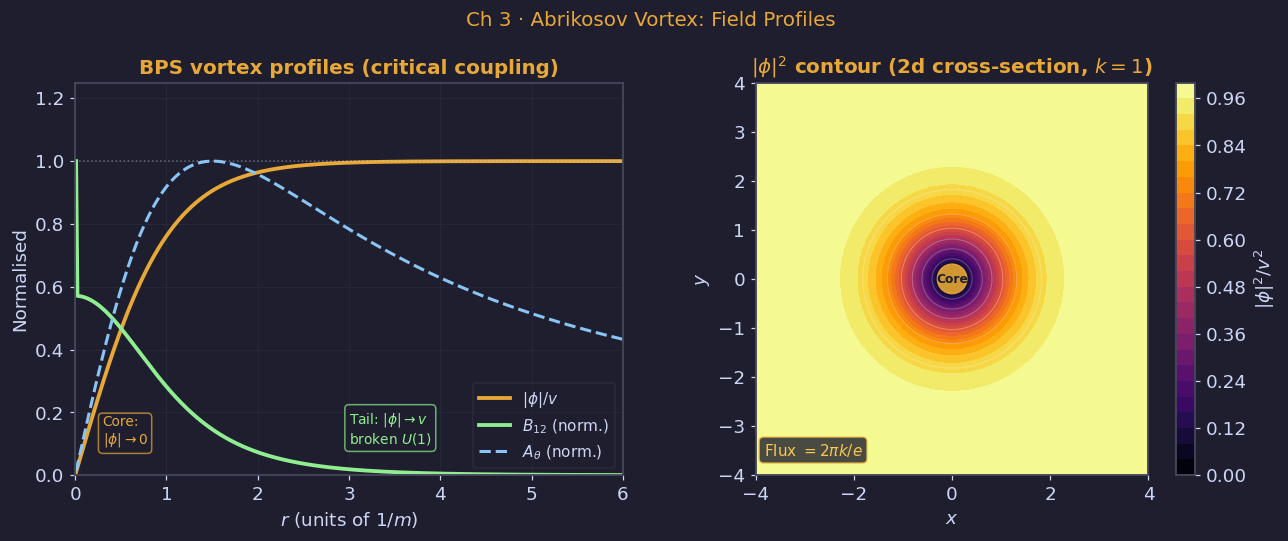

Saved: soliton_visualizations/ch03_fig01_vortex_profile.png


In [6]:
# ── fig01: vortex profile (Abrikosov vortex) ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 3 · Abrikosov Vortex: Field Profiles", color=AMB, fontsize=13)

r = np.linspace(0.01, 6.0, 400)
# Approximate BPS profiles: |phi| ~ tanh(r), A_theta ~ (1-sech(r))/r
phi_prof = np.tanh(r)
A_prof   = (1.0 - 1.0/np.cosh(r)) / r
B_prof   = np.gradient(r * A_prof, r) / r   # B = (1/r)d(rA)/dr schematic
B_prof   = np.abs(B_prof); B_prof /= B_prof.max()

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"BPS vortex profiles (critical coupling)", color=AMB)
ax.plot(r, phi_prof,  color=AMB,  lw=2.5, label=r'$|\phi|/v$')
ax.plot(r, B_prof,    color=GREEN,lw=2.5, label=r'$B_{12}$ (norm.)')
ax.plot(r, A_prof/A_prof.max(), color=BLUE, lw=2.0, ls='--',
        label=r'$A_\theta$ (norm.)')
ax.axhline(1.0, color=FG, ls=':', lw=1, alpha=0.4)
ax.set_xlabel(r'$r$ (units of $1/m$)'); ax.set_ylabel('Normalised')
ax.set_ylim(0, 1.25); ax.set_xlim(0, 6)
ax.legend(fontsize=10); ax.grid(True, alpha=0.2)
ax.text(0.05, 0.08, "Core:\n" + r"$|\phi|\to 0$", transform=ax.transAxes,
        fontsize=9, color=AMB, bbox=dict(boxstyle='round', fc=BG, ec=AMB, alpha=0.7))
ax.text(0.50, 0.08, r"Tail: $|\phi|\to v$" + "\nbroken $U(1)$",
        transform=ax.transAxes, fontsize=9, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.7))

# Right: 2d contour of |phi|^2
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"$|\phi|^2$ contour (2d cross-section, $k=1$)", color=AMB)
x = np.linspace(-4, 4, 200); y = np.linspace(-4, 4, 200)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
phi2 = np.tanh(R)**2
cf = ax2.contourf(X, Y, phi2, levels=25, cmap='inferno')
plt.colorbar(cf, ax=ax2, label=r'$|\phi|^2/v^2$')
ax2.contour(X, Y, phi2, levels=8, colors='white', alpha=0.25, linewidths=0.7)
ax2.add_patch(plt.Circle((0,0), 0.3, color=AMB, zorder=5, alpha=0.9))
ax2.text(0, 0, 'Core', ha='center', va='center', fontsize=8,
         color=BG, fontweight='bold', zorder=6)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$'); ax2.set_aspect('equal')
ax2.text(0.02, 0.05, r'Flux $= 2\pi k/e$', transform=ax2.transAxes,
         fontsize=10, color=YELL,
         bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.8))
plt.tight_layout()
save('ch03_fig01_vortex_profile.png', fig)


## Plot 6: Ch 3 · Vortices — 90° Scattering via Geodesic Approximation

Left: two-vortex moduli space $\mathrm{Sym}^2(\mathbf{R}^2)$ — Kähler, positions as holomorphic coordinates.
Right: head-on collision gives $90°$ scattering — a universal hallmark of BPS soliton dynamics.


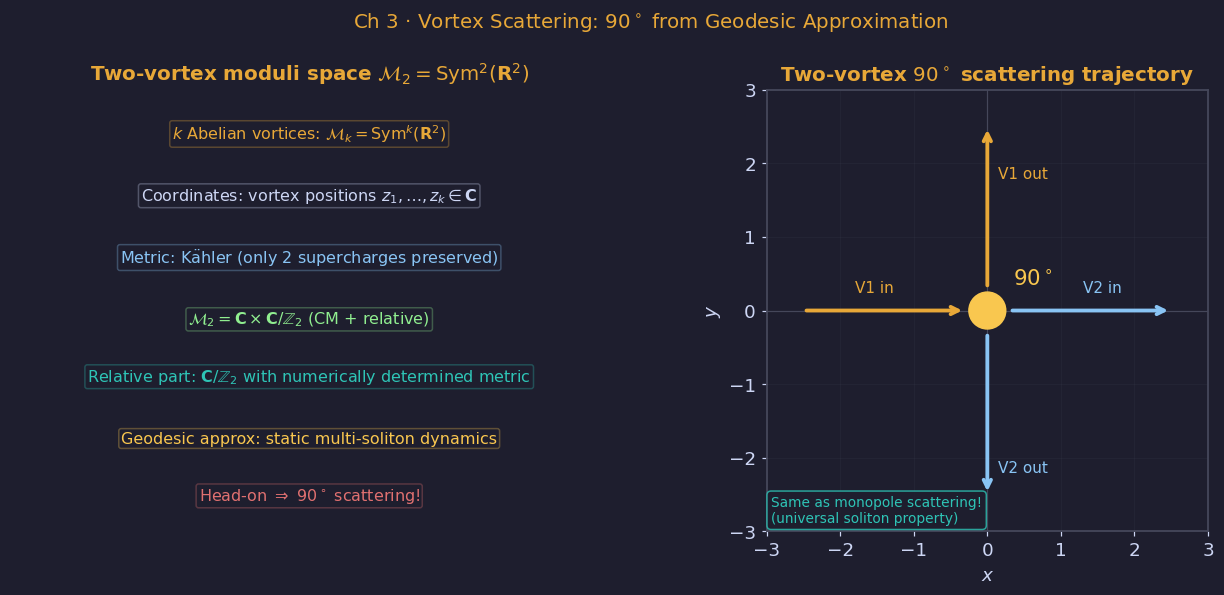

Saved: soliton_visualizations/ch03_fig02_vortex_scattering.png


In [7]:
# ── fig02: vortex 90-degree scattering ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r"Ch 3 · Vortex Scattering: $90^\circ$ from Geodesic Approximation",
             color=AMB, fontsize=13)

# Left: moduli space Sym^2(R^2)
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r"Two-vortex moduli space $\mathcal{M}_2 = \mathrm{Sym}^2(\mathbf{R}^2)$",
             color=AMB)
items = [
    (0.50, 0.90, r"$k$ Abelian vortices: $\mathcal{M}_k = \mathrm{Sym}^k(\mathbf{R}^2)$", AMB),
    (0.50, 0.76, r"Coordinates: vortex positions $z_1,\ldots,z_k\in\mathbf{C}$", FG),
    (0.50, 0.62, r"Metric: K$\ddot{\rm a}$hler (only 2 supercharges preserved)", BLUE),
    (0.50, 0.48, r"$\mathcal{M}_2 = \mathbf{C}\times\mathbf{C}/\mathbb{Z}_2$ (CM + relative)", GREEN),
    (0.50, 0.35, r"Relative part: $\mathbf{C}/\mathbb{Z}_2$ with numerically determined metric", TEAL),
    (0.50, 0.21, r"Geodesic approx: static multi-soliton dynamics", YELL),
    (0.50, 0.08, r"Head-on $\Rightarrow$ $90^\circ$ scattering!", RED),
]
for (x, y, txt, col) in items:
    ax.text(x, y, txt, ha='center', va='center', fontsize=10.5,
            color=col, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))

# Right: 90-degree scattering
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"Two-vortex $90^\circ$ scattering trajectory", color=AMB)
ax2.annotate('', xy=(-0.3, 0), xytext=(-2.5, 0),
             arrowprops=dict(arrowstyle='->', color=AMB, lw=2.5))
ax2.annotate('', xy=( 2.5, 0), xytext=( 0.3, 0),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax2.annotate('', xy=(0,  2.5), xytext=(0,  0.3),
             arrowprops=dict(arrowstyle='->', color=AMB, lw=2.5))
ax2.annotate('', xy=(0, -2.5), xytext=(0, -0.3),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax2.text(-1.8,  0.25, "V1 in",  color=AMB,  fontsize=10)
ax2.text( 1.3,  0.25, "V2 in",  color=BLUE, fontsize=10)
ax2.text( 0.15, 1.8,  "V1 out", color=AMB,  fontsize=10)
ax2.text( 0.15,-2.2,  "V2 out", color=BLUE, fontsize=10)
ax2.add_patch(plt.Circle((0,0), 0.25, color=YELL, zorder=5))
ax2.text(0.35, 0.35, r"$90^\circ$", fontsize=14, color=YELL)
ax2.set_xlim(-3,3); ax2.set_ylim(-3,3); ax2.set_aspect('equal')
ax2.axhline(0, color=EDGE, lw=0.8); ax2.axvline(0, color=EDGE, lw=0.8)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$'); ax2.grid(True, alpha=0.15)
ax2.text(0.01, 0.02, "Same as monopole scattering!\n(universal soliton property)",
         transform=ax2.transAxes, fontsize=9, color=TEAL,
         bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.8))
plt.tight_layout()
save('ch03_fig02_vortex_scattering.png', fig)


## Plot 7: Ch 4 · Domain Walls — BPS Kink Profile

Left: BPS kink $\phi(z)=v\tanh(vz/\sqrt{2})$ interpolating between vacua $\pm v$; energy density is localised.
Right: three consecutive walls with topological ordering — walls cannot pass through each other.


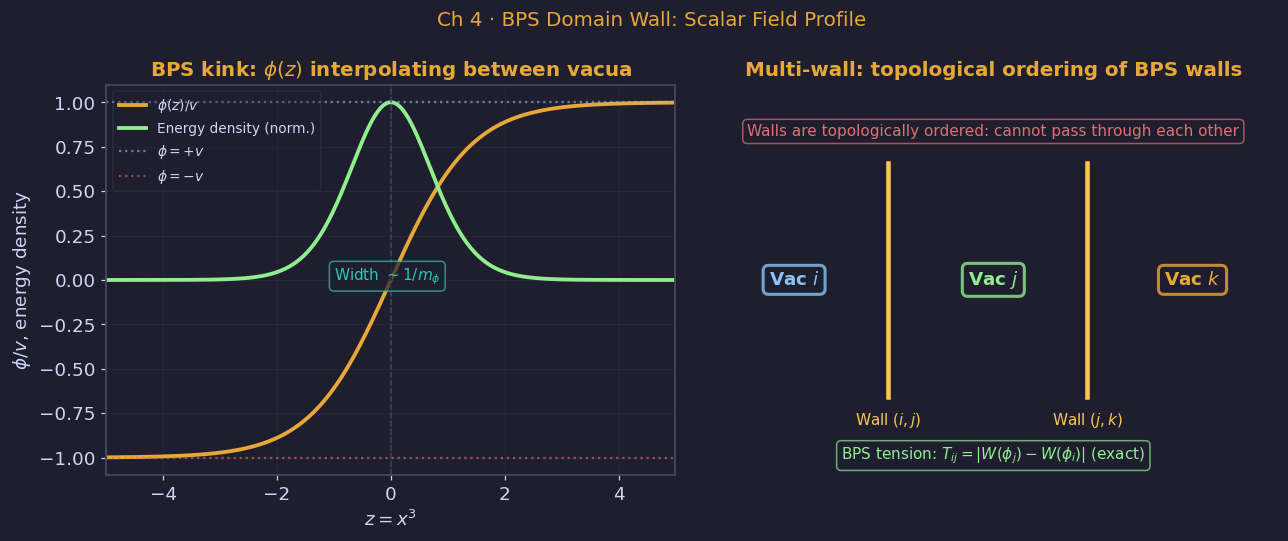

Saved: soliton_visualizations/ch04_fig01_domain_wall_profile.png


In [8]:
# ── fig01: domain wall profile ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 4 · BPS Domain Wall: Scalar Field Profile", color=AMB, fontsize=13)

z = np.linspace(-5, 5, 400)
v = 1.0
# BPS kink: phi = v * tanh(v*z/sqrt(2)) for V = lambda/4*(phi^2-v^2)^2
phi_kink = v * np.tanh(v * z / np.sqrt(2))
# Energy density: T_{00} = (dphi/dz)^2 = v^4/2 * sech^4(v*z/sqrt(2))
energy   = (v**2 / np.sqrt(2))**2 / np.cosh(v * z / np.sqrt(2))**4

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"BPS kink: $\phi(z)$ interpolating between vacua", color=AMB)
ax.plot(z, phi_kink/v, color=AMB, lw=2.5, label=r'$\phi(z)/v$')
ax.plot(z, energy/energy.max(), color=GREEN, lw=2.5, label=r'Energy density (norm.)')
ax.axhline( 1.0, color=BLUE, ls=':', lw=1.5, alpha=0.6, label=r'$\phi=+v$')
ax.axhline(-1.0, color=RED,  ls=':', lw=1.5, alpha=0.6, label=r'$\phi=-v$')
ax.axvline( 0.0, color=EDGE, ls='--', lw=1.0)
ax.set_xlabel(r'$z = x^3$'); ax.set_ylabel(r'$\phi/v$, energy density')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2); ax.set_xlim(-5, 5)
ax.text(0.40, 0.50, r"Width $\sim 1/m_\phi$", transform=ax.transAxes,
        fontsize=10, color=TEAL,
        bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))

# Right: multi-wall schematic
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r"Multi-wall: topological ordering of BPS walls", color=AMB)
vacua  = [r"Vac $i$", r"Vac $j$", r"Vac $k$"]
colors = [BLUE, GREEN, AMB]
xpos   = [0.15, 0.50, 0.85]
for x, label, col in zip(xpos, vacua, colors):
    ax2.text(x, 0.50, label, ha='center', va='center', fontsize=12,
             fontweight='bold', color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=col, lw=2, alpha=0.8))

# Wall boundaries
for xw, lbl in [(0.315, r"Wall $(i,j)$"), (0.665, r"Wall $(j,k)$")]:
    ax2.plot([xw, xw], [0.20, 0.80], color=YELL, lw=3, transform=ax2.transAxes)
    ax2.text(xw, 0.14, lbl, ha='center', va='center', fontsize=10,
             color=YELL, transform=ax2.transAxes)

ax2.text(0.50, 0.88, r"Walls are topologically ordered: cannot pass through each other",
         ha='center', va='center', fontsize=10, color=RED, transform=ax2.transAxes,
         bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.7))
ax2.text(0.50, 0.05, r"BPS tension: $T_{ij} = |W(\phi_j)-W(\phi_i)|$ (exact)",
         ha='center', va='center', fontsize=10, color=GREEN, transform=ax2.transAxes,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.7))
plt.tight_layout()
save('ch04_fig01_domain_wall_profile.png', fig)


## Plot 8: Ch 4 · Domain Walls — Complete Soliton Web (Revised)

Four solitons with their worldvolume theories; arrows show the embedding chain.
Hanany-Tong duality connects the 4d $\mathcal{N}=2$ SQCD to the 2d $\mathbb{CP}^{N-1}$ sigma-model.


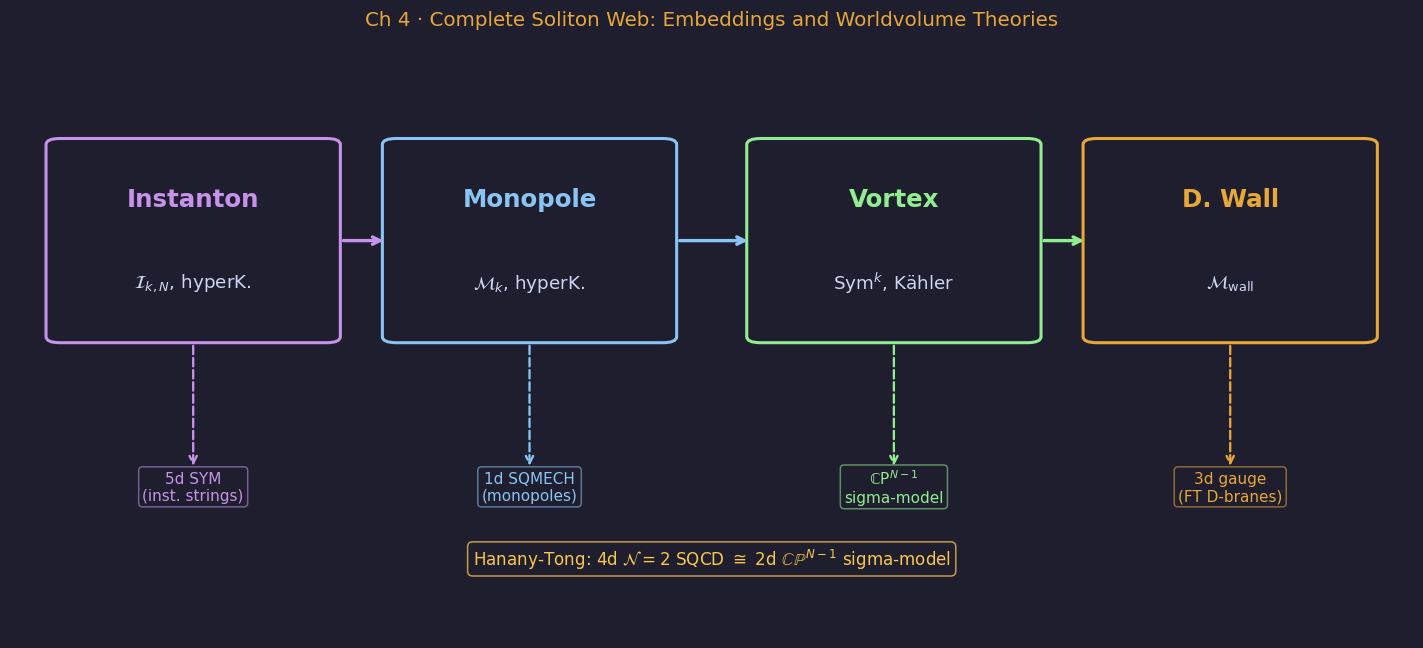

Saved: soliton_visualizations/ch04_fig03_soliton_web.png


In [9]:
# ── fig03: soliton web / embeddings (revised v2) ─────────────────────────
fig, ax = plt.subplots(figsize=(13, 6))
fig.suptitle("Ch 4 · Complete Soliton Web: Embeddings and Worldvolume Theories",
             color=AMB, fontsize=13, y=0.97)
ax.set_facecolor(BG); ax.axis('off')

# ── 박스 좌표: 4개 균등, 좌우 여백 확보 ──────────────────────────────────
BOX_W, BOX_H = 0.19, 0.32
BOX_Y0 = 0.50
BOX_CY = BOX_Y0 + BOX_H / 2
CXS = [0.13, 0.37, 0.63, 0.87]   # 중심 x; 좌끝=0.035, 우끝=0.965

nodes = [
    (CXS[0], "Instanton", r"$\mathcal{I}_{k,N}$, hyperK.", PURP),
    (CXS[1], "Monopole",  r"$\mathcal{M}_k$, hyperK.",      BLUE),
    (CXS[2], "Vortex",    "Sym$^k$, K\u00e4hler",           GREEN),  # ä = unicode
    (CXS[3], "D. Wall",   r"$\mathcal{M}_{\rm wall}$",       AMB),
]

for (cx, name, sub, col) in nodes:
    rect = FancyBboxPatch((cx - BOX_W/2, BOX_Y0), BOX_W, BOX_H,
                          boxstyle="round,pad=0.01", lw=2,
                          edgecolor=col, facecolor=BG, transform=ax.transAxes)
    ax.add_patch(rect)
    ax.text(cx, BOX_CY + 0.07, name,
            ha='center', va='center', fontsize=16, fontweight='bold',
            color=col, transform=ax.transAxes)
    ax.text(cx, BOX_CY - 0.07, sub,
            ha='center', va='center', fontsize=12,
            color=FG, transform=ax.transAxes)

# ── 수평 화살표: 박스 경계 정확히 연결 ───────────────────────────────────
for i in range(3):
    x_start = CXS[i]   + BOX_W/2
    x_end   = CXS[i+1] - BOX_W/2
    col     = nodes[i][3]
    ax.annotate('', xy=(x_end-0.007, BOX_CY), xytext=(x_start +0.01, BOX_CY),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color=col, lw=2.2))

# ── Worldvolume theories: 박스 하단 → 레이블 ─────────────────────────────
WV_Y = 0.17
wv = [
    (CXS[0], "5d SYM\n(inst. strings)",              PURP),
    (CXS[1], "1d SQMECH\n(monopoles)",                BLUE),
    (CXS[2], "\u2102P$^{N-1}$\nsigma-model",         GREEN),
    (CXS[3], "3d gauge\n(FT D-branes)",               AMB),
]
for (cx, lbl, col) in wv:
    ax.annotate('', xy=(cx, WV_Y + 0.11), xytext=(cx, BOX_Y0 - 0.01),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', color=col, lw=1.5,
                                linestyle='dashed'))
    ax.text(cx, WV_Y+0.08, lbl,
            ha='center', va='center', fontsize=10, color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=col, alpha=0.55))

# ── Hanany-Tong duality ───────────────────────────────────────────────────
ax.text(0.50, 0.13,
        r"Hanany-Tong: 4d $\mathcal{N}=2$ SQCD $\cong$ 2d $\mathbb{CP}^{N-1}$ sigma-model",
        ha='center', va='center', fontsize=11, color=YELL,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELL, alpha=0.75))

fig.subplots_adjust(top=0.93, bottom=0.02, left=0.01, right=0.99)
save('ch04_fig03_soliton_web.png', fig)

## Download All Visualizations


In [10]:
# ── Download all as zip ───────────────────────────────────────────────────
import shutil
shutil.make_archive('soliton_visualizations', 'zip', 'soliton_visualizations')
try:
    from google.colab import files
    files.download('soliton_visualizations.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — saved to soliton_visualizations/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
